Imports and load data

In [1]:

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, pearsonr, spearmanr, probplot

sns.set_theme(style="whitegrid")

# Replace with your local file path
df = pd.read_csv("amazon_uk_products.csv")

df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


Quick cleaning

In [3]:
# Keep only columns we need if they exist
cols_needed = ["category", "isBestSeller", "price", "stars", "rating", "reviews"]
existing_cols = [c for c in cols_needed if c in df.columns]
df = df[existing_cols].copy()

# Basic null handling
df = df.dropna(subset=["category", "isBestSeller", "price", "stars"])

# Make sure data types are usable
if "isBestSeller" in df.columns:
    if df["isBestSeller"].dtype == "object":
        df["isBestSeller"] = df["isBestSeller"].astype(str).str.lower().map({
            "true": True, "false": False
        })

for col in ["price", "stars", "rating", "reviews"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.dropna(subset=["price", "stars"])
df.head()

,category,isBestSeller,price,stars,reviews
0,Hi-Fi Speakers,False,21.99,4.7,15308
1,Hi-Fi Speakers,True,23.99,4.7,98099
2,Hi-Fi Speakers,False,21.99,4.7,15308
3,Hi-Fi Speakers,False,31.99,4.7,7205
4,Hi-Fi Speakers,False,17.99,4.6,1881


# Part 1: Best-seller trends across categories

1. Crosstab

In [4]:
crosstab = pd.crosstab(df["category"], df["isBestSeller"])
crosstab

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


Proportion of best-sellers by category

In [5]:
best_seller_prop = (
    pd.crosstab(df["category"], df["isBestSeller"], normalize="index")
    .rename(columns={False: "not_best_seller", True: "best_seller"})
)

best_seller_prop = best_seller_prop.sort_values("best_seller", ascending=False)
best_seller_prop.head(20)

isBestSeller,not_best_seller,best_seller
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Mirrors,0.972000,0.028000


2. Chi-square test + Cramér’s V

In [6]:
contingency = pd.crosstab(df["category"], df["isBestSeller"])

chi2, p, dof, expected = chi2_contingency(contingency)

print("Chi-square statistic:", chi2)
print("p-value:", p)
print("Degrees of freedom:", dof)

Chi-square statistic: 36540.20270061387
p-value: 0.0
Degrees of freedom: 295


Cramér’s V

In [7]:
n = contingency.to_numpy().sum()
r, k = contingency.shape

cramers_v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
print("Cramér's V:", cramers_v)

Cramér's V: 0.1222829439760564


3. Stacked bar chart

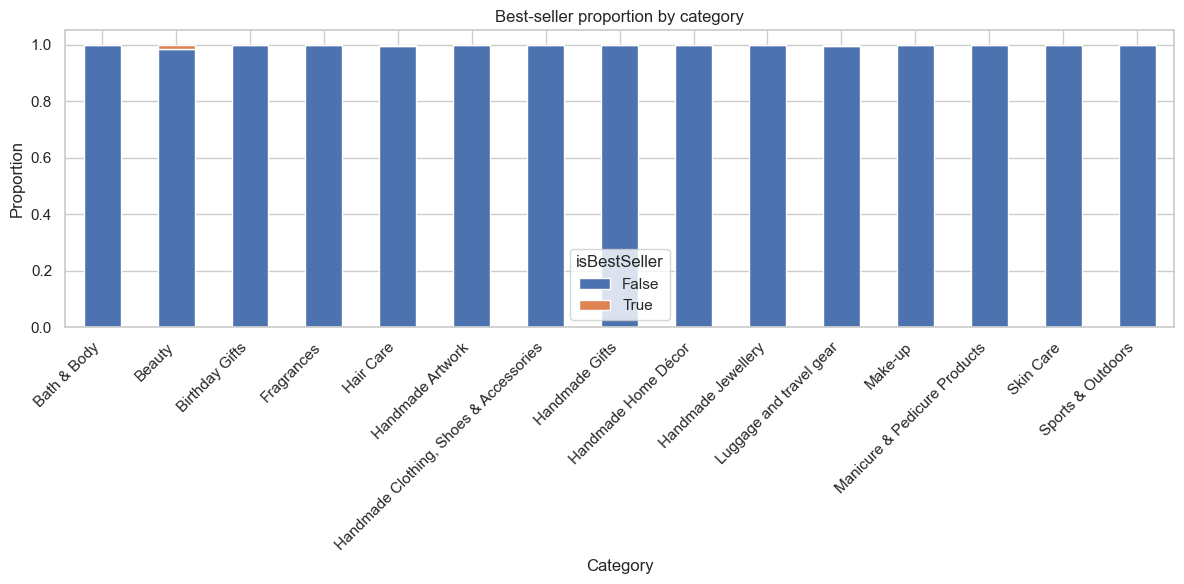

In [8]:
top_categories = df["category"].value_counts().head(15).index
plot_data = pd.crosstab(
    df[df["category"].isin(top_categories)]["category"],
    df[df["category"].isin(top_categories)]["isBestSeller"],
    normalize="index"
)

plot_data.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Best-seller proportion by category")
plt.ylabel("Proportion")
plt.xlabel("Category")
plt.xticks(rotation=45, ha="right")
plt.legend(title="isBestSeller")
plt.tight_layout()
plt.show()

# Part 2: Prices and ratings across categories and brands

0. Remove outliers in price using IQR

In [9]:
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

df_no_outliers = df[(df["price"] >= lower_bound) & (df["price"] <= upper_bound)].copy()

print("Original shape:", df.shape)
print("Without outliers:", df_no_outliers.shape)

Original shape: (2443651, 5)
Without outliers: (2115963, 5)


1. Violin plot of price by category


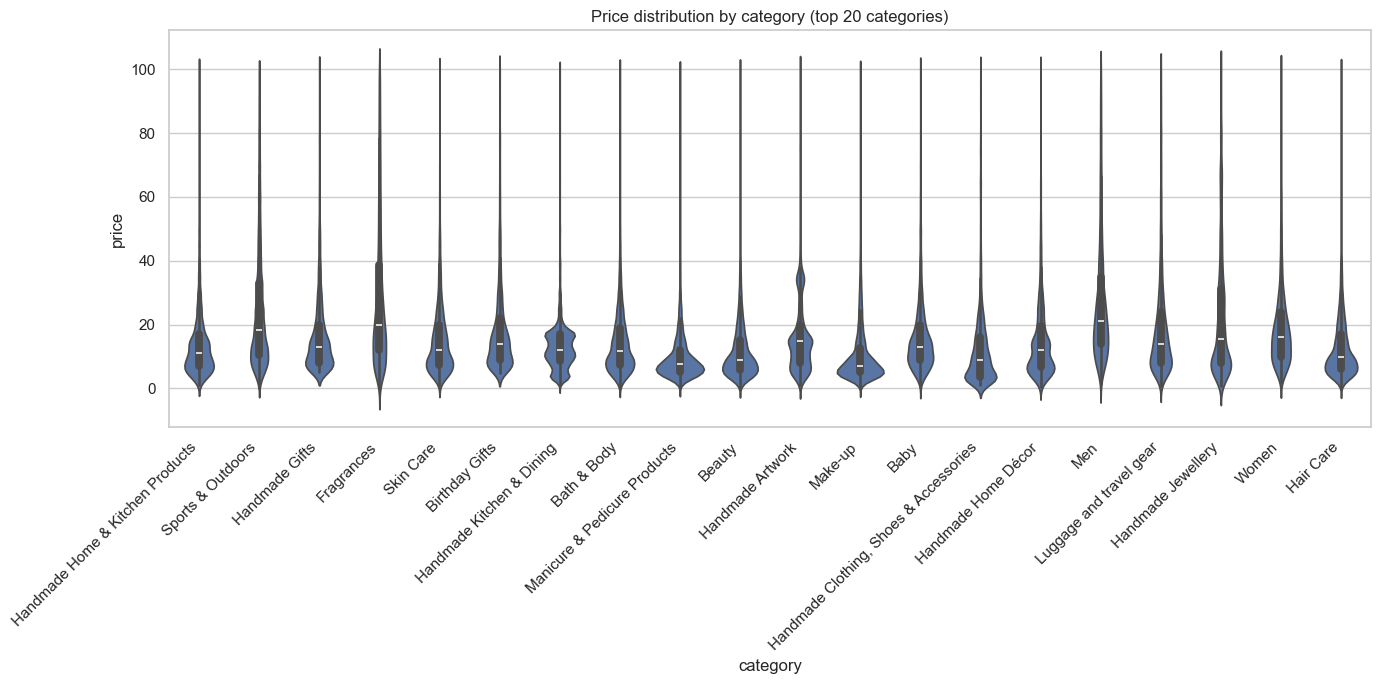

In [10]:
top20_categories = df_no_outliers["category"].value_counts().head(20).index
violin_data = df_no_outliers[df_no_outliers["category"].isin(top20_categories)]

plt.figure(figsize=(14, 7))
sns.violinplot(data=violin_data, x="category", y="price")
plt.title("Price distribution by category (top 20 categories)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Category with highest median price, no filtering

In [11]:
median_price_by_category = (
    df_no_outliers.groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

median_price_by_category.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

2. Bar chart of average price for top 10 categories by count

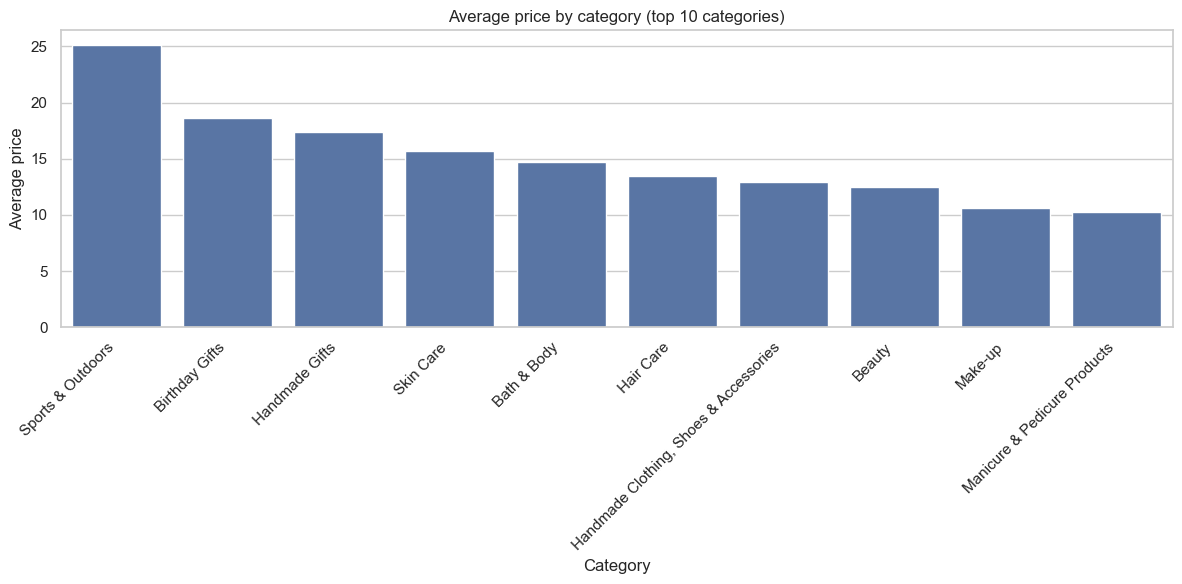

In [12]:
top10_categories = df_no_outliers["category"].value_counts().head(10).index
bar_data = (
    df_no_outliers[df_no_outliers["category"].isin(top10_categories)]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(x=bar_data.index, y=bar_data.values)
plt.title("Average price by category (top 10 categories)")
plt.ylabel("Average price")
plt.xlabel("Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Category with highest average price, no filtering

In [13]:
mean_price_by_category = (
    df_no_outliers.groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

mean_price_by_category.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

3. Box plots of stars by category

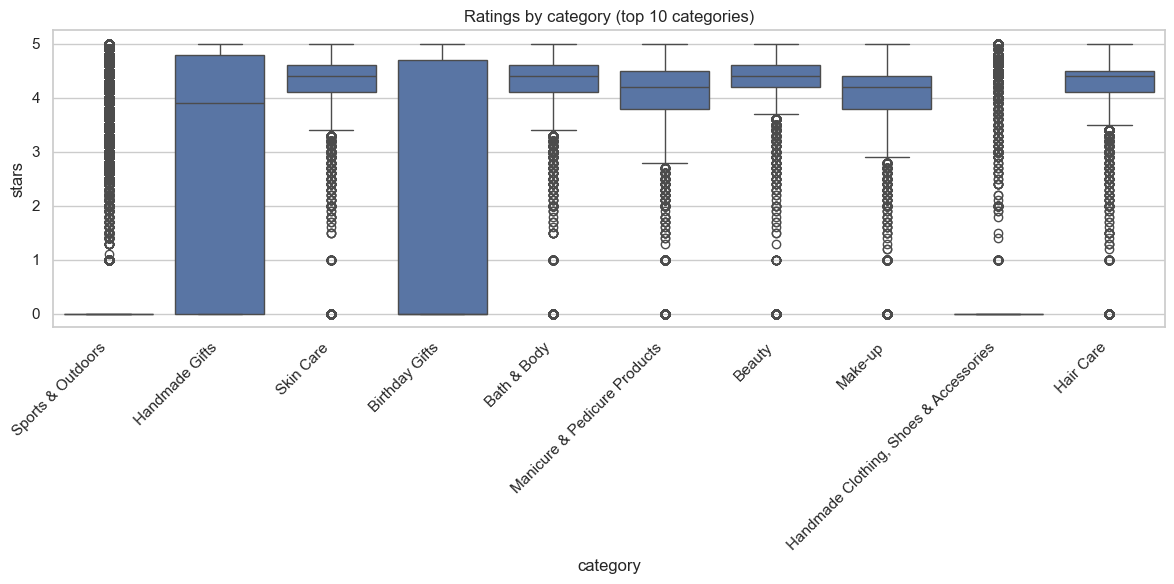

In [14]:
top10_categories_ratings = df_no_outliers["category"].value_counts().head(10).index
box_data = df_no_outliers[df_no_outliers["category"].isin(top10_categories_ratings)]

plt.figure(figsize=(12, 6))
sns.boxplot(data=box_data, x="category", y="stars")
plt.title("Ratings by category (top 10 categories)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

Category with highest median rating, no filtering

In [15]:
median_rating_by_category = (
    df_no_outliers.groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

median_rating_by_category.head(10)

category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64

# Part 3: Interplay between prices and ratings

1. Correlation coefficient between price and stars

In [16]:
pearson_corr, pearson_p = pearsonr(df_no_outliers["price"], df_no_outliers["stars"])
print("Pearson correlation:", pearson_corr)
print("Pearson p-value:", pearson_p)

Pearson correlation: -0.07767299878181222
Pearson p-value: 0.0


2. Scatter plot

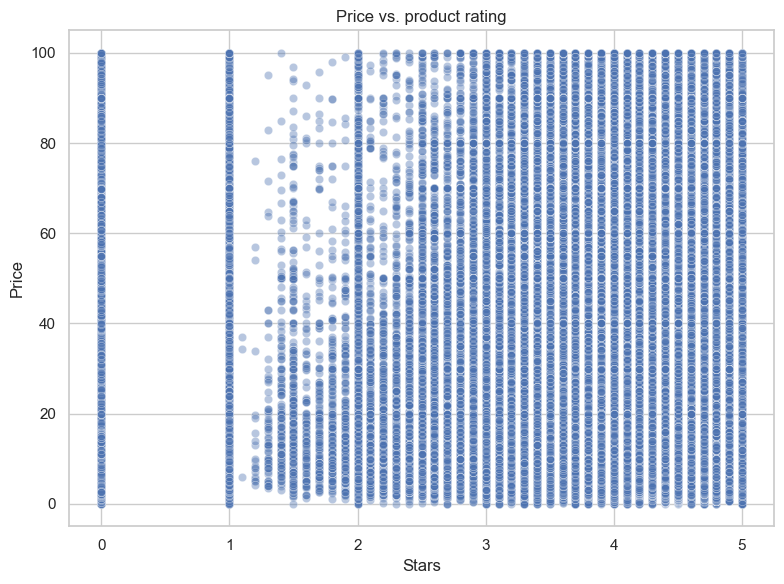

In [17]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_no_outliers, x="stars", y="price", alpha=0.4)
plt.title("Price vs. product rating")
plt.xlabel("Stars")
plt.ylabel("Price")
plt.tight_layout()
plt.show()

Correlation heatmap

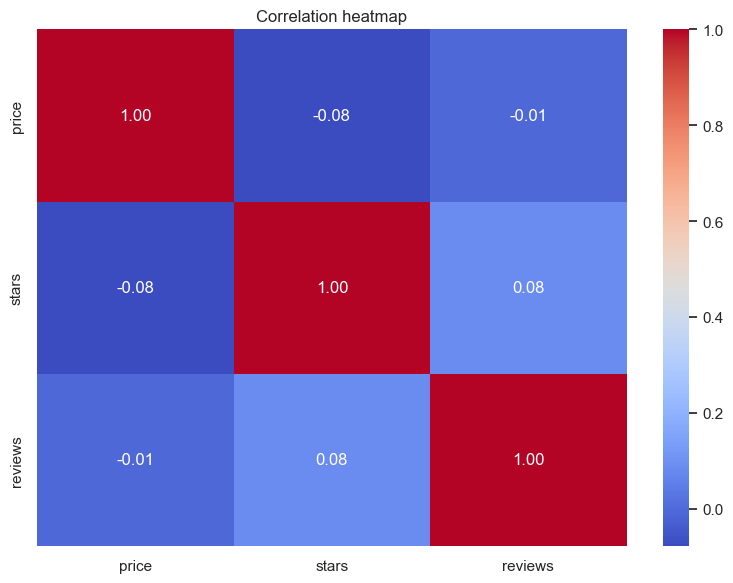

In [18]:
numeric_df = df_no_outliers.select_dtypes(include=np.number)

plt.figure(figsize=(8, 6))
sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation heatmap")
plt.tight_layout()
plt.show()

QQ plot for price

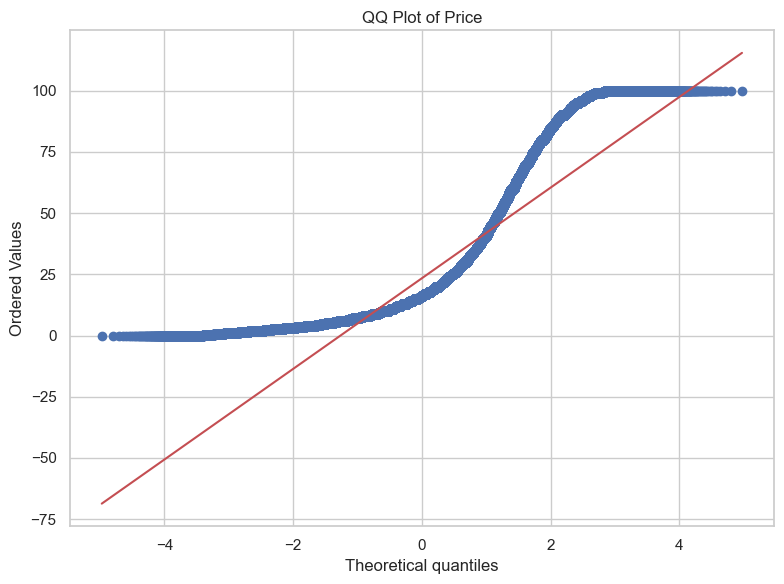

In [19]:
plt.figure(figsize=(8, 6))
probplot(df_no_outliers["price"], dist="norm", plot=plt)
plt.title("QQ Plot of Price")
plt.tight_layout()
plt.show()